In [2]:
import pandas as pd

config = pd.read_csv(
    "../outputs/hybrid/hybrid_config_train_selected.csv"
)

BEST_W = float(config["BEST_W"].iloc[0])
BEST_VW = float(config["BEST_VW"].iloc[0])
FINAL_THRESHOLD = float(config["FINAL_THRESHOLD"].iloc[0])

print("Loaded configuration:")
print("BEST_W =", BEST_W)
print("BEST_VW =", BEST_VW)
print("FINAL_THRESHOLD =", FINAL_THRESHOLD)

Loaded configuration:
BEST_W = 0.8
BEST_VW = 0.2
FINAL_THRESHOLD = 0.45


In [3]:


import pandas as pd
from pathlib import Path

BASE_DIR = Path("../outputs")
HYBRID_DIR = BASE_DIR / "hybrid"
PLOTS_DIR = BASE_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

df_cl_test = pd.read_csv("../outputs/hybrid/classical_test_outputs.csv")
df_qm_test = pd.read_csv("../outputs/hybrid/quantum_test_outputs.csv")

df_test = df_cl_test.merge(
    df_qm_test,
    on=["sample_id", "y_true"],
    how="inner"
)

print("Classical test:", df_cl_test.shape)
print("Quantum test:", df_qm_test.shape)
print("Merged test:", df_test.shape)
print(df_test.head())

Classical test: (154, 4)
Quantum test: (154, 4)
Merged test: (154, 6)
   sample_id  y_true  xgb_proba  xgb_pred  vqc_proba  vqc_pred
0          0       0   0.657923         1   0.506344         1
1          1       0   0.309509         0   0.478453         0
2          2       0   0.651757         1   0.497248         0
3          3       0   0.002570         0   0.413627         0
4          4       0   0.858612         1   0.640525         1


In [4]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    matthews_corrcoef, confusion_matrix
)
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

HYBRID_DIR = Path("../outputs/hybrid")


df_tr = pd.read_csv(HYBRID_DIR / "classical_train_outputs.csv")
df_qt = pd.read_csv(HYBRID_DIR / "quantum_train_outputs.csv")
df_te = pd.read_csv(HYBRID_DIR / "classical_test_outputs.csv")
df_qe = pd.read_csv(HYBRID_DIR / "quantum_test_outputs.csv")

df_train = df_tr.merge(df_qt, on=['sample_id','y_true'])
df_test  = df_te.merge(df_qe, on=['sample_id','y_true'])

y_train = df_train['y_true'].values
y_true  = df_test['y_true'].values

print(f"Train: {df_train.shape} | Test: {df_test.shape}")


def fit_q_cal(probs, y, n_bins=10):
    fraction_pos, mean_pred = calibration_curve(
        y, probs, n_bins=n_bins, strategy='quantile'
    )
    sort_idx     = np.argsort(mean_pred)
    mean_pred    = mean_pred[sort_idx]
    fraction_pos = fraction_pos[sort_idx]
    mp = np.concatenate([[0.0],             mean_pred,    [1.0]])
    fp = np.concatenate([[fraction_pos[0]], fraction_pos, [fraction_pos[-1]]])
    return mp, fp

def apply_q_cal(probs, mp, fp):
    return np.clip(np.interp(probs, mp, fp), 0.0, 1.0)


xgb_mp, xgb_fp = fit_q_cal(df_train['xgb_proba'].values, y_train)

df_test['calibrated_xgb_proba'] = apply_q_cal(
    df_test['xgb_proba'].values, xgb_mp, xgb_fp
)
df_test['calibrated_vqc_proba'] = df_test['vqc_proba'].values  # raw — preserves 84% AUC


print(f"\nVerification:")
print(f"  XGB cal AUC: {roc_auc_score(y_true, df_test['calibrated_xgb_proba'])*100:.2f}%")
print(f"  VQC cal AUC: {roc_auc_score(y_true, df_test['calibrated_vqc_proba'])*100:.2f}%")
print(f"  XGB cal range: [{df_test['calibrated_xgb_proba'].min():.4f}, {df_test['calibrated_xgb_proba'].max():.4f}]")
print(f"  VQC cal range: [{df_test['calibrated_vqc_proba'].min():.4f}, {df_test['calibrated_vqc_proba'].max():.4f}]")


BEST_W = 0.5
BEST_VW = 0.5
FINAL_THRESHOLD = 0.45

df_test['hybrid_score'] = (
    BEST_W  * df_test['calibrated_xgb_proba'] +
    BEST_VW * df_test['calibrated_vqc_proba']
)
df_test['hybrid_pred'] = (df_test['hybrid_score'] >= FINAL_THRESHOLD).astype(int)

hybrid_score = df_test['hybrid_score'].values
hybrid_pred  = df_test['hybrid_pred'].values


tn, fp, fn, tp = confusion_matrix(y_true, hybrid_pred).ravel()

print(f"\nFinal Hybrid Metrics (XGB calibrated + VQC raw):")
print(f"  Accuracy    : {accuracy_score(y_true, hybrid_pred)*100:.2f}%")
print(f"  Precision   : {precision_score(y_true, hybrid_pred, zero_division=0)*100:.2f}%")
print(f"  Recall      : {recall_score(y_true, hybrid_pred, zero_division=0)*100:.2f}%")
print(f"  Specificity : {tn/(tn+fp)*100:.2f}%")
print(f"  F1          : {f1_score(y_true, hybrid_pred, zero_division=0)*100:.2f}%")
print(f"  MCC         : {matthews_corrcoef(y_true, hybrid_pred):.4f}")
print(f"  ROC-AUC     : {roc_auc_score(y_true, hybrid_score)*100:.2f}%")
print(f"  PR-AUC      : {average_precision_score(y_true, hybrid_score)*100:.2f}%")
print(f"  TN={tn} FP={fp} FN={fn} TP={tp}")


df_test.to_csv(
    HYBRID_DIR / "final_hybrid_predictions_train_calibrated.csv",
    index=False
)


joblib.dump((xgb_mp, xgb_fp), HYBRID_DIR / "xgb_calibrator_train.pkl")


final_metrics = {
    "Accuracy"       : round(accuracy_score(y_true, hybrid_pred)*100, 2),
    "Precision"      : round(precision_score(y_true, hybrid_pred, zero_division=0)*100, 2),
    "Recall"         : round(recall_score(y_true, hybrid_pred, zero_division=0)*100, 2),
    "Specificity"    : round(tn/(tn+fp)*100, 2),
    "F1"             : round(f1_score(y_true, hybrid_pred, zero_division=0)*100, 2),
    "MCC"            : round(matthews_corrcoef(y_true, hybrid_pred), 4),
    "ROC_AUC"        : round(roc_auc_score(y_true, hybrid_score)*100, 2),
    "PR_AUC"         : round(average_precision_score(y_true, hybrid_score)*100, 2),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    "Fusion_XGB"     : BEST_W,
    "Fusion_VQC"     : BEST_VW,
    "Threshold"      : FINAL_THRESHOLD,
    "XGB_calibration": "Quantile (10 bins, train-fitted)",
    "VQC_calibration": "None — non-monotonic mapping detected, raw probs used",
    "n_test"         : 154,
}
pd.DataFrame([final_metrics]).to_csv(
    HYBRID_DIR / "final_hybrid_metrics_train_calibrated.csv",
    index=False
)

print(f"\n✓ Saved: final_hybrid_predictions_train_calibrated.csv")
print(f"✓ Saved: final_hybrid_metrics_train_calibrated.csv")
print(f"✓ Saved: xgb_calibrator_train.pkl")
print(f"\nAll variables defined:")
print(f"  y_true, hybrid_score, hybrid_pred, df_test, df_train")
print(f"  BEST_W={BEST_W}, BEST_VW={BEST_VW}, FINAL_THRESHOLD={FINAL_THRESHOLD}")
print(f"  fit_q_cal, apply_q_cal, xgb_mp, xgb_fp")

Train: (614, 6) | Test: (154, 6)

Verification:
  XGB cal AUC: 87.48%
  VQC cal AUC: 84.07%
  XGB cal range: [0.0000, 0.9839]
  VQC cal range: [0.2041, 0.7980]

Final Hybrid Metrics (XGB calibrated + VQC raw):
  Accuracy    : 83.77%
  Precision   : 75.44%
  Recall      : 79.63%
  Specificity : 86.00%
  F1          : 77.48%
  MCC         : 0.6486
  ROC-AUC     : 88.13%
  PR-AUC      : 83.04%
  TN=86 FP=14 FN=11 TP=43

✓ Saved: final_hybrid_predictions_train_calibrated.csv
✓ Saved: final_hybrid_metrics_train_calibrated.csv
✓ Saved: xgb_calibrator_train.pkl

All variables defined:
  y_true, hybrid_score, hybrid_pred, df_test, df_train
  BEST_W=0.5, BEST_VW=0.5, FINAL_THRESHOLD=0.45
  fit_q_cal, apply_q_cal, xgb_mp, xgb_fp


In [5]:
df_test["hybrid_score"]
df_test["hybrid_pred"]
final_metrics
y_true

array([0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0])

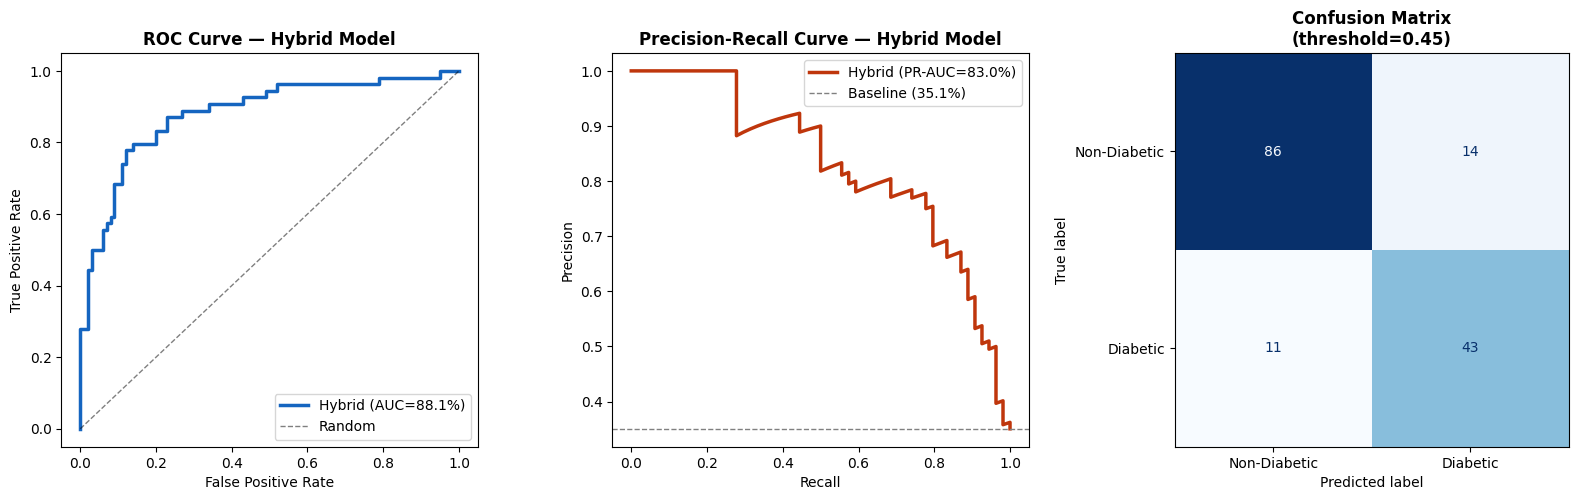

In [6]:


import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

hs = df_test["hybrid_score"].values
y_pred_hybrid = df_test["hybrid_pred"].values

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_true, hs)
axes[0].plot(
    fpr, tpr,
    color="#1565C0",
    lw=2.5,
    label=f'Hybrid (AUC={final_metrics["ROC_AUC"]:.1f}%)'
)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random")
axes[0].set_title("ROC Curve — Hybrid Model", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=10)

# Precision-recall curve
prp, prr, _ = precision_recall_curve(y_true, hs)
axes[1].plot(
    prr, prp,
    color="#BF360C",
    lw=2.5,
    label=f'Hybrid (PR-AUC={final_metrics["PR_AUC"]:.1f}%)'
)
axes[1].axhline(
    y_true.mean(),
    color="gray",
    ls="--",
    lw=1,
    label=f'Baseline ({y_true.mean()*100:.1f}%)'
)
axes[1].set_title("Precision-Recall Curve — Hybrid Model", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=10)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_hybrid)
ConfusionMatrixDisplay(
    cm,
    display_labels=["Non-Diabetic", "Diabetic"]
).plot(
    ax=axes[2],
    colorbar=False,
    cmap="Blues"
)
axes[2].set_title(
    f"Confusion Matrix\n(threshold={FINAL_THRESHOLD})",
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "Figure_4.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

df_test["hybrid_pred"] = y_pred_hybrid

Risk-stratification cutoffs derived from TRAINING hybrid scores
using the 33.3rd and 66.7th percentiles.

Low cutoff  : 0.3063
High cutoff : 0.4980

Risk Stratification Summary — Independent Test Set
Risk Group Observed Test Score Range  N Patients Observed Diabetes Rate  Mean Hybrid Score  Min Score  Max Score
       Low            [0.102, 0.303]          74                   8.1%             0.1966     0.1021     0.3026
  Moderate            [0.307, 0.481]          30                  30.0%             0.3927     0.3073     0.4809
      High            [0.499, 0.891]          50                  78.0%             0.7299     0.4985     0.8910


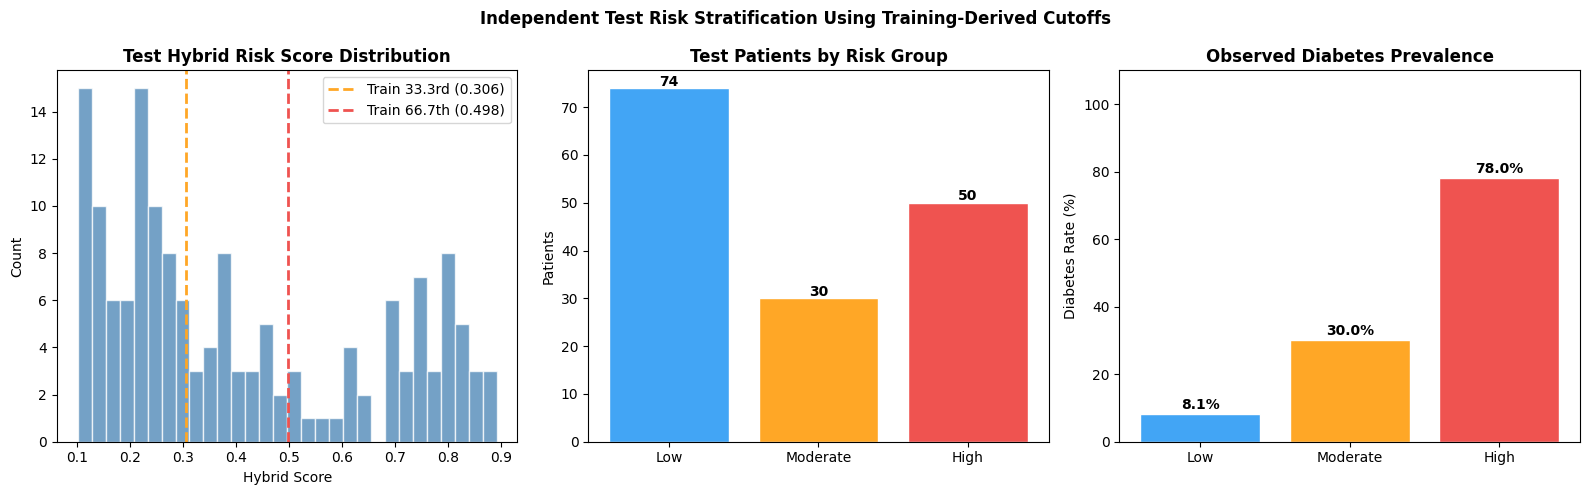


✓ Saved: risk_stratification_summary_test_train_cutoffs.csv
✓ Saved: risk_stratification_train_cutoffs.csv
✓ Saved: test_05_risk_stratification_train_cutoffs.png


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CREATE TRAIN HYBRID SCORES
# ============================================================

# Apply the training-fitted XGBoost calibrator to TRAIN probabilities
df_train["calibrated_xgb_proba"] = apply_q_cal(
    df_train["xgb_proba"].values,
    xgb_mp,
    xgb_fp
)

# VQC probabilities remain raw
df_train["calibrated_vqc_proba"] = df_train["vqc_proba"].values

# Build hybrid scores on TRAIN using the already selected fusion weights
df_train["hybrid_score"] = (
    BEST_W  * df_train["calibrated_xgb_proba"] +
    BEST_VW * df_train["calibrated_vqc_proba"]
)


# ============================================================
# 2. DERIVE RISK CUT-OFFS FROM TRAINING DISTRIBUTION ONLY
# ============================================================

low_cutoff = float(
    np.percentile(df_train["hybrid_score"].values, 33.3)
)

high_cutoff = float(
    np.percentile(df_train["hybrid_score"].values, 66.7)
)

print("Risk-stratification cutoffs derived from TRAINING hybrid scores")
print("using the 33.3rd and 66.7th percentiles.")
print()

print(f"Low cutoff  : {low_cutoff:.4f}")
print(f"High cutoff : {high_cutoff:.4f}")


# ============================================================
# 3. APPLY FIXED TRAIN-DERIVED CUT-OFFS TO TEST SET
# ============================================================

def assign_risk(score):
    if score < low_cutoff:
        return "Low"
    elif score < high_cutoff:
        return "Moderate"
    else:
        return "High"


df_test["risk_group"] = df_test["hybrid_score"].apply(assign_risk)

df_test["risk_group"] = pd.Categorical(
    df_test["risk_group"],
    categories=["Low", "Moderate", "High"],
    ordered=True
)


# ============================================================
# 4. SUMMARIZE RISK GROUPS ON THE INDEPENDENT TEST SET
# ============================================================

risk_rows = []

for grp in ["Low", "Moderate", "High"]:

    sub = df_test[df_test["risk_group"] == grp]

    risk_rows.append({
        "Risk Group": grp,
        "Observed Test Score Range":
            f'[{sub["hybrid_score"].min():.3f}, {sub["hybrid_score"].max():.3f}]'
            if len(sub) > 0 else "N/A",

        "N Patients": len(sub),

        "Observed Diabetes Rate":
            f'{sub["y_true"].mean()*100:.1f}%'
            if len(sub) > 0 else "N/A",

        "Mean Hybrid Score":
            round(sub["hybrid_score"].mean(), 4)
            if len(sub) > 0 else np.nan,

        "Min Score":
            round(sub["hybrid_score"].min(), 4)
            if len(sub) > 0 else np.nan,

        "Max Score":
            round(sub["hybrid_score"].max(), 4)
            if len(sub) > 0 else np.nan,
    })


df_risk_summary = pd.DataFrame(risk_rows)

print("\nRisk Stratification Summary — Independent Test Set")
print(df_risk_summary.to_string(index=False))


# ============================================================
# 5. SAVE SUMMARY
# ============================================================

df_risk_summary.to_csv(
    HYBRID_DIR / "risk_stratification_summary_test_train_cutoffs.csv",
    index=False
)


# Also save the training-derived cutoffs
risk_cutoff_df = pd.DataFrame([{
    "Low_Cutoff_33.3pct": low_cutoff,
    "High_Cutoff_66.7pct": high_cutoff,
    "Cutoff_Source": "Training hybrid score distribution"
}])

risk_cutoff_df.to_csv(
    HYBRID_DIR / "risk_stratification_train_cutoffs.csv",
    index=False
)


# ============================================================
# 6. PLOT TEST-SET RISK STRATIFICATION
# ============================================================

risk_colors = {
    "Low": "#42A5F5",
    "Moderate": "#FFA726",
    "High": "#EF5350"
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))


# ------------------------------------------------------------
# Plot 1: Test hybrid-score distribution with TRAIN cutoffs
# ------------------------------------------------------------

ax = axes[0]

ax.hist(
    df_test["hybrid_score"],
    bins=30,
    color="steelblue",
    edgecolor="white",
    alpha=0.75
)

ax.axvline(
    low_cutoff,
    color="#FFA726",
    linestyle="--",
    linewidth=2,
    label=f"Train 33.3rd ({low_cutoff:.3f})"
)

ax.axvline(
    high_cutoff,
    color="#EF5350",
    linestyle="--",
    linewidth=2,
    label=f"Train 66.7th ({high_cutoff:.3f})"
)

ax.set_title(
    "Test Hybrid Risk Score Distribution",
    fontweight="bold"
)

ax.set_xlabel("Hybrid Score")
ax.set_ylabel("Count")
ax.legend()


# ------------------------------------------------------------
# Plot 2: Number of TEST patients per risk group
# ------------------------------------------------------------

ax = axes[1]

group_counts = (
    df_test["risk_group"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"])
    .fillna(0)
)

bars = ax.bar(
    group_counts.index,
    group_counts.values,
    color=[risk_colors[g] for g in group_counts.index],
    edgecolor="white"
)

ax.set_title(
    "Test Patients by Risk Group",
    fontweight="bold"
)

ax.set_ylabel("Patients")

for bar, value in zip(bars, group_counts.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.5,
        str(int(value)),
        ha="center",
        fontweight="bold"
    )


# ------------------------------------------------------------
# Plot 3: Observed TEST diabetes prevalence
# ------------------------------------------------------------

ax = axes[2]

obs_rate = (
    df_test
    .groupby("risk_group", observed=True)["y_true"]
    .mean()
    * 100
)

obs_rate = obs_rate.reindex(
    ["Low", "Moderate", "High"]
)

bars = ax.bar(
    obs_rate.index,
    obs_rate.values,
    color=[risk_colors[g] for g in obs_rate.index],
    edgecolor="white"
)

ax.set_title(
    "Observed Diabetes Prevalence",
    fontweight="bold"
)

ax.set_ylabel("Diabetes Rate (%)")
ax.set_ylim(0, 110)

for bar, value in zip(bars, obs_rate.values):

    if pd.notna(value):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 1.5,
            f"{value:.1f}%",
            ha="center",
            fontweight="bold"
        )


plt.suptitle(
    "Independent Test Risk Stratification Using Training-Derived Cutoffs",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "test_05_risk_stratification_train_cutoffs.png",
    bbox_inches="tight"
)

plt.show()


print("\n✓ Saved: risk_stratification_summary_test_train_cutoffs.csv")
print("✓ Saved: risk_stratification_train_cutoffs.csv")
print("✓ Saved: test_05_risk_stratification_train_cutoffs.png")

In [8]:


import pandas as pd

_RECS = {
    "Low": (
        "Estimated risk level: Low.\n"
        "This person appears to be maintaining a relatively healthy profile based "
        "on the available health indicators. Supporting maintenance of healthy "
        "lifestyle habits — including regular physical activity, balanced nutrition, "
        "and routine health monitoring — is encouraged. Continued periodic "
        "preventive check-ups are a positive and worthwhile step."
    ),
    "Moderate": (
        "Estimated risk level: Moderate.\n"
        "Some indicators suggest a moderately elevated risk profile. Gradual, "
        "sustainable lifestyle improvements may be beneficial. Encouraging regular "
        "glucose monitoring, weight management, and increased physical activity — "
        "at a pace that feels manageable — is recommended. Preventive health "
        "screening and consultation with a healthcare provider are advisable steps."
    ),
    "High": (
        "Estimated risk level: High.\n"
        "This person's profile is associated with a higher estimated risk based on "
        "the calibrated hybrid model. Individuals in the high-risk stratum may be "
        "encouraged to seek clinical assessment, where appropriate follow-up testing "
        "and individualized preventive guidance can be considered by qualified "
        "healthcare professionals. Communication should remain supportive and "
        "non-judgmental while respecting the individual's circumstances and "
        "capacity for change."
    ),
}

def get_recommendation(risk_group):
    return _RECS.get(str(risk_group), "Risk group not recognised.")


df_test["recommendation"] = (
    df_test["risk_group"]
    .astype(str)
    .apply(get_recommendation)
)

print("MI-Based Recommendation Examples")
print("=" * 72)

for grp in ["Low", "Moderate", "High"]:
    sub = df_test[df_test["risk_group"] == grp]

    if len(sub) == 0:
        print(f"\n[No samples in {grp} group]")
        continue

    row = sub.iloc[0]

    print(f"\nRisk Group   : {grp}")
    print(f"Sample ID    : {int(row['sample_id'])}")
    print(f"Hybrid Score : {row['hybrid_score']:.4f}")
    print(f"y_true       : {int(row['y_true'])}  (1=Diabetic, 0=Non-diabetic)")
    print()
    print(row["recommendation"])
    print("-" * 72)


recommendation_summary = (
    df_test
    .groupby("risk_group", observed=True)
    .agg(
        N=("sample_id", "count"),
        MeanScore=("hybrid_score", "mean"),
        DiabetesRate=("y_true", "mean")
    )
    .reset_index()
)

recommendation_summary["MeanScore"] = recommendation_summary["MeanScore"].round(4)
recommendation_summary["DiabetesRate"] = (
    recommendation_summary["DiabetesRate"] * 100
).round(1).astype(str) + "%"

print("\nRecommendation Summary:")
print(recommendation_summary.to_string(index=False))


df_test.to_csv(
    HYBRID_DIR / "final_hybrid_predictions_with_recommendations.csv",
    index=False
)

recommendation_summary.to_csv(
    HYBRID_DIR / "recommendation_summary_test.csv",
    index=False
)

print("\nSaved:")
print(HYBRID_DIR / "final_hybrid_predictions_with_recommendations.csv")
print(HYBRID_DIR / "recommendation_summary_test.csv")

MI-Based Recommendation Examples

Risk Group   : Low
Sample ID    : 1
Hybrid Score : 0.3011
y_true       : 0  (1=Diabetic, 0=Non-diabetic)

Estimated risk level: Low.
This person appears to be maintaining a relatively healthy profile based on the available health indicators. Supporting maintenance of healthy lifestyle habits — including regular physical activity, balanced nutrition, and routine health monitoring — is encouraged. Continued periodic preventive check-ups are a positive and worthwhile step.
------------------------------------------------------------------------

Risk Group   : Moderate
Sample ID    : 8
Hybrid Score : 0.3782
y_true       : 0  (1=Diabetic, 0=Non-diabetic)

Estimated risk level: Moderate.
Some indicators suggest a moderately elevated risk profile. Gradual, sustainable lifestyle improvements may be beneficial. Encouraging regular glucose monitoring, weight management, and increased physical activity — at a pace that feels manageable — is recommended. Preventi

c:\Users\shanm\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


XGBoost model : xgb_model.pkl
X_test        : (154, 8)
Columns       : ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


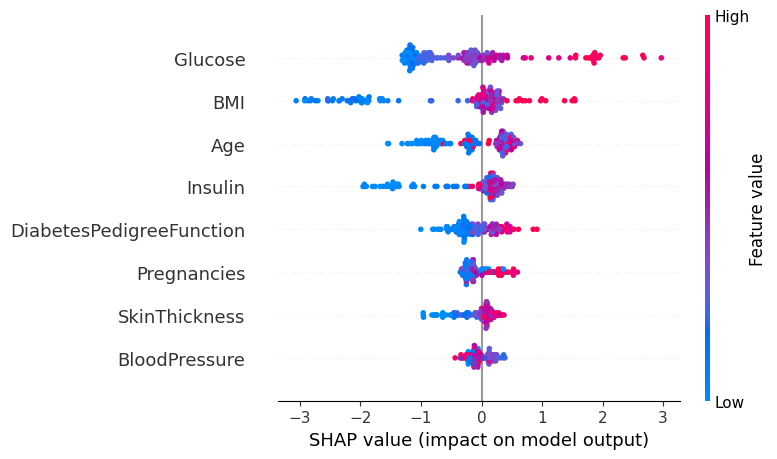

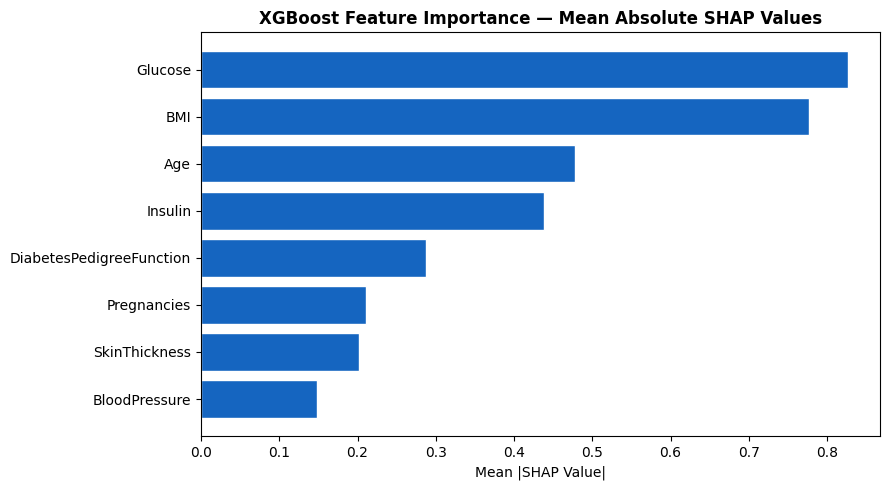


Top features:
                 Feature  Mean |SHAP|
                 Glucose     0.826237
                     BMI     0.777399
                     Age     0.478097
                 Insulin     0.438848
DiabetesPedigreeFunction     0.287755
             Pregnancies     0.211003
           SkinThickness     0.201599
           BloodPressure     0.147657

Saved:
C:\Users\shanm\OneDrive\Desktop\Final Notebooks\outputs\hybrid\shap_feature_importance_test.csv


In [9]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

XGB_MODEL_PATH = HYBRID_DIR / "xgb_model.pkl"
X_TEST_CL_PATH = HYBRID_DIR / "X_test_classical.csv"

shap_ready = XGB_MODEL_PATH.exists() and X_TEST_CL_PATH.exists()

if not shap_ready:
    print("=" * 70)
    print("SHAP PLACEHOLDER — Required files not found")
    print("=" * 70)
    print(f"{XGB_MODEL_PATH.name:<30}: {'FOUND' if XGB_MODEL_PATH.exists() else 'MISSING'}")
    print(f"{X_TEST_CL_PATH.name:<30}: {'FOUND' if X_TEST_CL_PATH.exists() else 'MISSING'}")
    print()
    print("Required files:")
    print("  xgb_model.pkl")
    print("  X_test_classical.csv")
    print()
    print("NOTE: SHAP is applied only to the XGBoost branch.")
    print("The VQC branch is not explained with SHAP.")
else:
    try:
        import shap

        xgb_loaded = joblib.load(XGB_MODEL_PATH)
        X_test_cl = pd.read_csv(X_TEST_CL_PATH)

        print(f"XGBoost model : {XGB_MODEL_PATH.name}")
        print(f"X_test        : {X_test_cl.shape}")
        print(f"Columns       : {list(X_test_cl.columns)}")

        if hasattr(xgb_loaded, "named_steps"):
            clf = xgb_loaded.named_steps.get(
                "clf",
                list(xgb_loaded.named_steps.values())[-1]
            )
        else:
            clf = xgb_loaded

        explainer = shap.TreeExplainer(clf)
        shap_values = explainer.shap_values(X_test_cl)

        if isinstance(shap_values, list):
            sv = shap_values[1]
        else:
            sv = shap_values

        # SHAP summary dot plot
        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            sv,
            X_test_cl,
            plot_type="dot",
            show=False
        )
        plt.tight_layout()
        plt.savefig(
            PLOTS_DIR / "Figure_5_SHAP_Summary.pdf",
            format="pdf",
            bbox_inches="tight",
            pad_inches=0.05
            )
        plt.show()

       
        mean_abs = np.abs(sv).mean(axis=0)

        shap_df = pd.DataFrame({
            "Feature": X_test_cl.columns,
            "Mean |SHAP|": mean_abs
        })

        shap_df = shap_df.sort_values(
            "Mean |SHAP|",
            ascending=True
        )

        fig, ax = plt.subplots(
            figsize=(9, max(5, len(shap_df) * 0.45))
        )

        ax.barh(
            shap_df["Feature"],
            shap_df["Mean |SHAP|"],
            color="#1565C0",
            edgecolor="white"
        )

        ax.set_xlabel("Mean |SHAP Value|")
        ax.set_title(
            "XGBoost Feature Importance — Mean Absolute SHAP Values",
            fontweight="bold"
        )

        plt.tight_layout()
        plt.savefig(
            PLOTS_DIR / "test_07_shap_bar_xgboost.png",
            bbox_inches="tight"
        )
        plt.show()

        shap_df_sorted = shap_df.sort_values(
            "Mean |SHAP|",
            ascending=False
        )

        shap_df_sorted.to_csv(
            HYBRID_DIR / "shap_feature_importance_test.csv",
            index=False
        )

        print("\nTop features:")
        print(shap_df_sorted.head(8).to_string(index=False))
        print("\nSaved:")
        print(HYBRID_DIR / "shap_feature_importance_test.csv")

    except ImportError:
        print("SHAP is not installed. Run: !pip install shap")
    except Exception as e:
        print(f"SHAP error: {e}")
        print("Verify xgb_model.pkl is valid and X_test_classical.csv matches the model input features.")

In [10]:
# Patient #0 verification
print("\nPatient #0 values:")
print(df_test.iloc[0][['xgb_proba','calibrated_xgb_proba',
                        'vqc_proba','calibrated_vqc_proba',
                        'hybrid_score','hybrid_pred','y_true']])


Patient #0 values:
xgb_proba               0.657923
calibrated_xgb_proba    0.552825
vqc_proba               0.506344
calibrated_vqc_proba    0.506344
hybrid_score            0.529584
hybrid_pred                    1
y_true                         0
Name: 0, dtype: object
